<a href="https://colab.research.google.com/github/LUNALEE002/-/blob/main/MuJoCo_%EA%B8%B0%EC%B4%88_%EC%8B%9C%EB%AE%AC%EB%A0%88%EC%9D%B4%EC%85%98_%EC%B2%98%EC%9D%8C%EB%B6%80%ED%84%B0_%EB%A7%8C%EB%93%A4%EA%B8%B0_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧱 MuJoCo 기초 — 시뮬레이션을 처음부터 만들기

**CONNECT AI LAB · 유튜브 멤버십 라이브** · 2026-10-17

**두뇌를 만드는 것만큼, 두뇌가 만들어지는 세상을 만드는 것도 중요합니다.** 로봇 · 자율주행 · 드론의 두뇌는 현실이 아니라 시뮬레이터에서 수천 번 부서지며 배웁니다.

**MuJoCo** 는 딥마인드가 무료로 공개한 물리 엔진입니다 ([github.com/google-deepmind/mujoco](https://github.com/google-deepmind/mujoco)). 로봇 연구의 표준이고, Gymnasium 의 로봇 환경(Hopper · Ant · Humanoid)도 MuJoCo 위에서 돌아갑니다.
MuJoCo 에서는 **XML 몇 줄이 세상의 설계도**입니다. 오늘은 상자 하나 떨어뜨리기부터 시작해, 내 세상에 두뇌를 붙여 학습시키는 데까지 갑니다.

| CELL | 배우는 것 |
|---|---|
| 01 | 설치 · 화면 그리기 준비 |
| 02 | **첫 세상** — 바닥 · 빛 · 떨어지는 상자 |
| 03 | 모양과 재질 — 공은 구르고 상자는 미끄러진다 |
| 04 | **관절** — 진자(돌기) · 미끄럼(미끄러지기) |
| 05 | **모터** — 내가 힘을 주면 움직인다 |
| 06 | **센서** — 두뇌가 볼 숫자 |
| 07 | 카메라 — 보는 자리 바꾸기 |
| 08 | **Gymnasium 으로 감싸기** — 카트폴 XML 을 정식 환경으로 |
| 09 | **두뇌 붙이기** — 5강의 DQN 으로 500점 |
| 10 | 세상 바꾸기 — 달 중력 · 막대 두 배 |
| 11 | 보너스 — MuJoCo 착지선 (다리가 진짜로 닿는다) |
| 12 | 다음 — Gymnasium 의 MuJoCo 로봇 |

> ▶ **먼저 「런타임 → 런타임 유형 변경 → T4 GPU」** (화면 그리기용 · 가장 확실) → **런타임 → 모두 실행** · 약 10분. CPU 런타임이면 그리기 도구를 따로 설치합니다.

## CELL 01 · 설치 · 화면 그리기 준비

In [1]:
!pip install -q mujoco "gymnasium[mujoco]>=1.0" imageio-ffmpeg
!apt-get -qq install -y fonts-nanum > /dev/null 2>&1
import os, sys, subprocess
if sys.platform == 'darwin': os.environ['MUJOCO_GL'] = 'cgl'
else:
    try:
        subprocess.check_output('nvidia-smi'); os.environ['MUJOCO_GL'] = 'egl'          # GPU 런타임 — 가장 확실
    except Exception:
        print('CPU 런타임 — 화면 그리기 도구(OSMesa)를 설치합니다 (1분)…')
        subprocess.run('apt-get -qq update > /dev/null 2>&1; apt-get -qq install -y libosmesa6 libosmesa6-dev libgl1 > /dev/null 2>&1', shell=True)
        os.environ['MUJOCO_GL'] = 'osmesa'; os.environ['PYOPENGL_PLATFORM'] = 'osmesa'
try:
    import mujoco
    _t = mujoco.Renderer(mujoco.MjModel.from_xml_string('<mujoco><worldbody><geom type="sphere" size=".1"/></worldbody></mujoco>'), 32, 32); _t.close()
except Exception as e:
    raise SystemExit('❌ 화면 그리기를 준비하지 못했습니다 → 메뉴 「런타임 → 런타임 유형 변경 → T4 GPU」 로 바꾸고 「런타임 → 세션 다시 시작」 후 다시 실행하세요. (' + str(e)[:80] + ')')
import mujoco, math, time, random, base64
import numpy as np, imageio, matplotlib, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import gymnasium as gym
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env
from PIL import Image, ImageDraw, ImageFont
from IPython.display import HTML, display
글꼴경로 = next((p for p in ['/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf', '/System/Library/Fonts/Supplemental/AppleGothic.ttf'] if os.path.exists(p)), None)
if 글꼴경로:
    matplotlib.font_manager.fontManager.addfont(글꼴경로); plt.rcParams['font.family'] = matplotlib.font_manager.FontProperties(fname=글꼴경로).get_name()
plt.rcParams['axes.unicode_minus'] = False
def 글꼴(n):
    try: return ImageFont.truetype(글꼴경로, n)
    except Exception: return ImageFont.load_default()
torch.set_num_threads(1)

def 사진(m, d, 카메라=-1, 제목=''):
    """지금 세상을 한 장 찍는다"""
    r = mujoco.Renderer(m, 360, 640); r.update_scene(d, camera=카메라); im = Image.fromarray(r.render())
    if 제목: ImageDraw.Draw(im).text((14, 10), 제목, fill=(184, 255, 92), font=글꼴(20))
    display(im)

def 영상(m, d, 초=3.0, 카메라=-1, 제목='', 매걸음=None, 파일=None, fps=30):
    """세상을 몇 초 동안 움직이며 찍는다. 매걸음(m, d) 함수로 모터에 힘을 줄 수 있다"""
    r = mujoco.Renderer(m, 360, 640); 화면들 = []; 다음 = 0.0
    while d.time < 초:
        if 매걸음: 매걸음(m, d)
        mujoco.mj_step(m, d)
        if d.time >= 다음:
            r.update_scene(d, camera=카메라); im = Image.fromarray(r.render())
            if 제목: ImageDraw.Draw(im).text((14, 10), 제목, fill=(184, 255, 92), font=글꼴(20))
            화면들.append(np.array(im)); 다음 += 1 / fps
    파일 = 파일 or f'mj_{int(time.time()*1000)}.mp4'
    imageio.mimsave(파일, 화면들, fps=fps, macro_block_size=1)
    display(HTML(f'<video width="560" controls autoplay loop muted><source src="data:video/mp4;base64,{base64.b64encode(open(파일, "rb").read()).decode()}" type="video/mp4"></video>'))
print('✅ MuJoCo', mujoco.__version__, '· 화면 그리기', os.environ['MUJOCO_GL'])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.8/232.8 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.6/30.6 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 13.7 MB/s eta 0:00:00
✅ MuJoCo 3.16.0 · 화면 그리기 egl


## CELL 02 · 첫 세상 — 바닥 · 빛 · 떨어지는 상자

MuJoCo 의 설계도는 이렇게 생겼습니다.

| 태그 | 뜻 |
|---|---|
| `<mujoco>` | 세상 전체 |
| `<option gravity=...>` | 세상의 규칙 (중력, 시간 간격) |
| `<worldbody>` | 세상 안에 놓인 것들 |
| `<geom>` | 모양 (평면 · 상자 · 공 · 캡슐 …) — 부딪히는 몸 |
| `<body>` | 움직이는 물체. 안에 geom 을 넣는다 |
| `<freejoint/>` | 이 물체는 자유롭게 떨어지고 굴러도 된다 |

In [2]:
첫세상 = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <visual><headlight ambient=".5 .5 .5"/></visual>
  <asset><texture name="격자" type="2d" builtin="checker" rgb1=".14 .16 .2" rgb2=".2 .22 .27" width="300" height="300"/>
         <material name="바닥재" texture="격자" texrepeat="6 6"/></asset>
  <worldbody>
    <light pos="0 0 4"/>
    <camera name="앞" pos="0 -3 1.2" xyaxes="1 0 0 0 .35 1"/>
    <geom name="바닥" type="plane" size="3 3 .1" material="바닥재"/>
    <body name="상자" pos="0 0 1.5" euler="20 30 0">
      <freejoint/>
      <geom type="box" size=".15 .15 .15" rgba="1 .83 .28 1"/>
    </body>
  </worldbody>
</mujoco>"""
m = mujoco.MjModel.from_xml_string(첫세상); d = mujoco.MjData(m)
print('물체 수(body):', m.nbody, '· 모양 수(geom):', m.ngeom, '· 한 걸음 시간:', m.opt.timestep, '초')
영상(m, d, 초=2.5, 카메라='앞', 제목='첫 세상 — 상자 하나 떨어뜨리기', 파일='mjb_01_box.mp4')

물체 수(body): 2 · 모양 수(geom): 2 · 한 걸음 시간: 0.002 초


## CELL 03 · 모양과 재질 — 공은 구르고 상자는 미끄러진다

같은 경사면에 공과 상자를 놓습니다. 다른 건 **모양** 하나. `friction` 으로 미끄러운 정도도 바꿀 수 있습니다.

In [3]:
경사면 = """
<mujoco>
  <visual><headlight ambient=".5 .5 .5"/></visual>
  <worldbody>
    <light pos="0 0 4"/>
    <camera name="옆" pos="0 -3.2 1.0" xyaxes="1 0 0 0 .2 1"/>
    <geom name="바닥" type="plane" size="4 2 .1" rgba=".16 .18 .22 1"/>
    <geom name="경사" type="box" pos="0 0 .45" size="1.2 .6 .03" euler="0 18 0" rgba=".35 .4 .48 1" friction=".6 .005 .0001"/>
    <body name="공" pos="-.9 -.25 1.05"><freejoint/><geom type="sphere" size=".1" rgba=".56 .83 1 1"/></body>
    <body name="상자" pos="-.9 .25 1.05" euler="0 18 0"><freejoint/><geom type="box" size=".1 .1 .1" rgba="1 .83 .28 1"/></body>
  </worldbody>
</mujoco>"""
m = mujoco.MjModel.from_xml_string(경사면); d = mujoco.MjData(m)
영상(m, d, 초=3.0, 카메라='옆', 제목='파란 공은 구르고, 노란 상자는 미끄러진다(혹은 멈춘다)', 파일='mjb_02_slope.mp4')

## CELL 04 · 관절 — 진자(돌기) · 미끄럼(미끄러지기)

`<joint>` 가 물체가 **어떻게만 움직일 수 있는지** 정합니다. `hinge` 는 한 축으로 돌기, `slide` 는 한 방향으로 미끄러지기.
`d.qpos` 에 관절의 위치가 숫자로 들어 있습니다 — 이게 나중에 **두뇌가 보는 상태**가 됩니다.

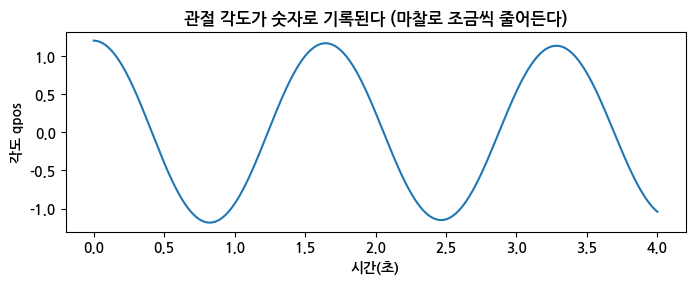

In [4]:
진자 = """
<mujoco>
  <visual><headlight ambient=".5 .5 .5"/></visual>
  <worldbody>
    <light pos="0 0 4"/>
    <camera name="앞" pos="0 -2.6 1.1" xyaxes="1 0 0 0 .1 1"/>
    <geom name="바닥" type="plane" size="3 3 .1" rgba=".16 .18 .22 1"/>
    <geom name="기둥" type="box" pos="0 0 .9" size=".4 .04 .02" rgba=".5 .5 .5 1"/>
    <body name="추" pos="0 0 .9">
      <joint name="돌기" type="hinge" axis="0 1 0" damping=".02"/>
      <geom type="capsule" fromto="0 0 0 0 0 -.6" size=".02" rgba=".9 .95 1 1"/>
      <geom type="sphere" pos="0 0 -.6" size=".07" rgba="1 .83 .28 1"/>
    </body>
  </worldbody>
</mujoco>"""
m = mujoco.MjModel.from_xml_string(진자); d = mujoco.MjData(m)
d.qpos[0] = 1.2                                   # 처음에 1.2 라디안(약 69도) 들어 올린 채로
기록 = []
def 적기(m, d): 기록.append((d.time, d.qpos[0]))
영상(m, d, 초=4.0, 카메라='앞', 제목='진자 — hinge 관절 하나', 매걸음=적기, 파일='mjb_03_pendulum.mp4')
t, q = zip(*기록); plt.figure(figsize=(8, 2.6)); plt.plot(t, q); plt.xlabel('시간(초)'); plt.ylabel('각도 qpos'); plt.title('관절 각도가 숫자로 기록된다 (마찰로 조금씩 줄어든다)'); plt.show()

## CELL 05 · 모터 — 내가 힘을 주면 움직인다

`<actuator><motor joint="..." gear="..."/>` 를 달면 `d.ctrl` 에 넣은 숫자만큼 힘이 들어갑니다. 지금은 **사람이 짠 규칙**으로 진자를 거꾸로 세워 봅니다(흔들어서 올리기). 다음엔 이 일을 **두뇌가 배웁니다.**

In [5]:
모터진자 = 진자.replace('</worldbody>', '</worldbody>\n  <actuator><motor joint="돌기" gear="1" ctrlrange="-2 2"/></actuator>')
m = mujoco.MjModel.from_xml_string(모터진자); d = mujoco.MjData(m)
def 흔들어올리기(m, d):
    q, w = d.qpos[0], d.qvel[0]
    거꾸로 = math.cos(q - math.pi)                # 1 이면 꼭대기
    if 거꾸로 > 0.9: d.ctrl[0] = -8 * math.sin(q - math.pi) - 1.5 * w     # 꼭대기 근처 — 균형 잡기
    else: d.ctrl[0] = 2.0 if w >= 0 else -2.0                               # 아래 — 흔드는 방향으로 힘 주기
영상(m, d, 초=6.0, 카메라='앞', 제목='모터 — 사람이 짠 규칙으로 흔들어 올리기', 매걸음=흔들어올리기, 파일='mjb_04_motor.mp4')

## CELL 06 · 센서 — 두뇌가 볼 숫자

`<sensor>` 로 원하는 숫자를 꺼냅니다. 관절 위치 · 속도 · 가속도 · 닿은 힘 … 무엇을 보여 주느냐가 **상태 설계**입니다 — 너무 적으면 두뇌가 모르고, 너무 많으면 헷갈립니다.

In [6]:
센서진자 = 모터진자.replace('</actuator>', '</actuator>\n  <sensor><jointpos joint="돌기" name="각도"/><jointvel joint="돌기" name="각속도"/></sensor>')
m = mujoco.MjModel.from_xml_string(센서진자); d = mujoco.MjData(m); d.qpos[0] = 0.8
for 걸음 in range(5):
    for _ in range(50): mujoco.mj_step(m, d)
    print(f'{d.time:4.2f}초 · 센서 → 각도 {d.sensordata[0]:+.3f} · 각속도 {d.sensordata[1]:+.3f}')
print('\n👉 두뇌가 받을 「상태」 = 이 숫자들. 두뇌가 낼 「행동」 = d.ctrl 에 넣을 힘.')

0.10초 · 센서 → 각도 +0.739 · 각속도 -1.202
0.20초 · 센서 → 각도 +0.563 · 각속도 -2.268
0.30초 · 센서 → 각도 +0.295 · 각속도 -2.997
0.40초 · 센서 → 각도 -0.021 · 각속도 -3.233
0.50초 · 센서 → 각도 -0.333 · 각속도 -2.918

👉 두뇌가 받을 「상태」 = 이 숫자들. 두뇌가 낼 「행동」 = d.ctrl 에 넣을 힘.


## CELL 07 · 카메라 — 보는 자리 바꾸기

`<camera>` 를 여러 개 달면 같은 장면을 여러 자리에서 볼 수 있습니다. `pos` 는 카메라 위치, `xyaxes` 는 바라보는 방향.

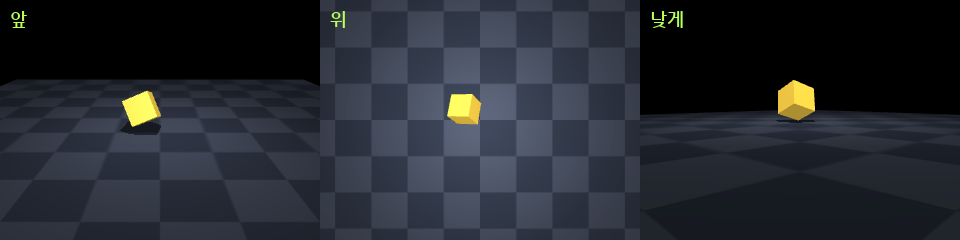

In [7]:
여러카메라 = 첫세상.replace('<camera name="앞" pos="0 -3 1.2" xyaxes="1 0 0 0 .35 1"/>',
    '<camera name="앞" pos="0 -3 1.2" xyaxes="1 0 0 0 .35 1"/><camera name="위" pos="0 0 4" xyaxes="1 0 0 0 1 0"/><camera name="낮게" pos="2.2 -2.2 .25" xyaxes=".7 .7 0 -.05 .05 1"/>')
m = mujoco.MjModel.from_xml_string(여러카메라); d = mujoco.MjData(m)
for _ in range(400): mujoco.mj_step(m, d)
r = mujoco.Renderer(m, 240, 320); 사진들 = []
for c in ['앞', '위', '낮게']:
    r.update_scene(d, camera=c); im = Image.fromarray(r.render()); ImageDraw.Draw(im).text((10, 8), c, fill=(184, 255, 92), font=글꼴(18)); 사진들.append(np.array(im))
display(Image.fromarray(np.concatenate(사진들, axis=1)))

## CELL 08 · Gymnasium 으로 감싸기 — 카트폴 XML 을 정식 환경으로

이제 다섯 가지 재료를 채웁니다. **상태**(수레 위치 · 속도 · 막대 각도 · 각속도 = `qpos`, `qvel`) · **행동**(모터를 왼쪽/오른쪽으로) · **보상**(버틴 걸음마다 +1) · **끝**(막대가 12도 넘게 기울거나 레일 끝) · **그리기**(카메라).

/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:317: UserWarning: WARN: A Box observation space minimum value is -infinity. This is probably too low.
  logger.warn(
/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:321: UserWarning: WARN: A Box observation space maximum value is infinity. This is probably too high.
  logger.warn(
/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:440: UserWarning: WARN: Not able to test alternative render modes due to the environment not having a spec. Try instantiating the environment through `gymnasium.make`
  logger.warn(


✅ check_env 통과 — XML 로 만든 세상이 정식 Gymnasium 환경이 됐습니다


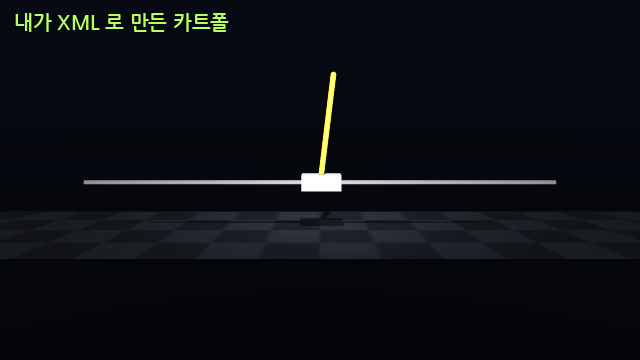

🎲 무작위로 20판 → 평균 24.95 걸음 (최대 500)


In [8]:
카트폴_XML = """
<mujoco model="나만의 카트폴">
  <option timestep="0.01" gravity="0 0 -9.81"/>
  <visual><headlight ambient=".45 .45 .45" diffuse=".6 .6 .6"/></visual>
  <asset><texture name="하늘" type="skybox" builtin="gradient" rgb1=".05 .07 .12" rgb2="0 0 0" width="200" height="200"/>
         <texture name="격자" type="2d" builtin="checker" rgb1=".12 .14 .17" rgb2=".18 .2 .24" width="300" height="300"/>
         <material name="바닥재" texture="격자" texrepeat="8 2"/></asset>
  <worldbody>
    <light pos="0 -2 3" dir="0 1 -1"/>
    <camera name="옆" pos="0 -4.4 1.05" xyaxes="1 0 0 0 0.12 1"/>
    <geom name="바닥" type="plane" size="4 1 0.1" material="바닥재"/>
    <geom name="레일" type="box" pos="0 0 0.5" size="2.4 0.02 0.02" rgba=".5 .5 .5 1" contype="0" conaffinity="0"/>
    <body name="수레" pos="0 0 0.5">
      <joint name="밀기" type="slide" axis="1 0 0" range="-2.4 2.4" limited="true" damping="0.1"/>
      <geom type="box" size="0.2 0.12 0.08" mass="1" rgba=".9 .95 1 1"/>
      <body name="막대" pos="0 0 0.08">
        <joint name="기울기" type="hinge" axis="0 1 0" damping="0.01"/>
        <geom type="capsule" fromto="0 0 0 0 0 1.0" size="0.03" mass="0.1" rgba="1 .83 .28 1"/>
      </body>
    </body>
  </worldbody>
  <actuator><motor joint="밀기" gear="10" ctrlrange="-1 1"/></actuator>
</mujoco>"""
class MJ카트폴(gym.Env):
    def __init__(self, xml=카트폴_XML):
        self.m = mujoco.MjModel.from_xml_string(xml); self.d = mujoco.MjData(self.m)
        self.action_space = spaces.Discrete(2); self.observation_space = spaces.Box(-np.inf, np.inf, (4,), np.float32)
    def _o(self): return np.array([self.d.qpos[0], self.d.qvel[0], self.d.qpos[1], self.d.qvel[1]], np.float32)
    def reset(self, seed=None, options=None):
        super().reset(seed=seed); mujoco.mj_resetData(self.m, self.d)
        self.d.qpos[:] = self.np_random.uniform(-0.05, 0.05, 2); self.d.qvel[:] = self.np_random.uniform(-0.05, 0.05, 2); self.t = 0
        mujoco.mj_forward(self.m, self.d); return self._o(), {}
    def step(self, a):
        self.d.ctrl[0] = 1.0 if a == 1 else -1.0
        for _ in range(2): mujoco.mj_step(self.m, self.d)      # 0.02초
        self.t += 1; o = self._o(); 끝 = bool(abs(o[0]) > 2.3 or abs(o[2]) > 0.21)
        return o, 1.0, 끝, self.t >= 500, {}

e = MJ카트폴(); check_env(e); print('✅ check_env 통과 — XML 로 만든 세상이 정식 Gymnasium 환경이 됐습니다')
o, _ = e.reset(seed=0); e.d.qpos[1] = 0.12; mujoco.mj_forward(e.m, e.d); 사진(e.m, e.d, '옆', '내가 XML 로 만든 카트폴')
L = []
for 씨 in range(20):
    o, _ = e.reset(seed=씨); 끝 = 잘림 = False; n = 0
    while not (끝 or 잘림): o, r_, 끝, 잘림, _ = e.step(e.action_space.sample()); n += 1
    L.append(n)
print('🎲 무작위로 20판 → 평균', np.mean(L), '걸음 (최대 500)')

## CELL 09 · 두뇌 붙이기 — 5강의 DQN 그대로

Gymnasium 틀이라 **5강의 DQN 함수를 한 글자도 안 바꾸고** 붙입니다.

In [9]:
def 두뇌만들기(상태수, 행동수, 은닉=128):
    return nn.Sequential(nn.Linear(상태수, 은닉), nn.ReLU(), nn.Linear(은닉, 은닉), nn.ReLU(), nn.Linear(은닉, 행동수))
def DQN학습(환경, 상태수, 행동수, 총걸음, 은닉=128, 학습률=1e-3, 감마=0.99, 탐험기간=0.3, 목표주기=500, 학습시작=1000, 배치=64, 기억크기=50_000, 씨앗=0, 보고=5000, 평가=None):
    random.seed(씨앗); np.random.seed(씨앗); torch.manual_seed(씨앗)
    q = 두뇌만들기(상태수, 행동수, 은닉); 목표 = 두뇌만들기(상태수, 행동수, 은닉); 목표.load_state_dict(q.state_dict()); opt = torch.optim.Adam(q.parameters(), lr=학습률)
    S = np.zeros((기억크기, 상태수), np.float32); A = np.zeros(기억크기, np.int64); R = np.zeros(기억크기, np.float32); S2 = np.zeros((기억크기, 상태수), np.float32); D = np.zeros(기억크기, np.float32); k = 0; 찬 = 0
    s = 환경.reset(); 판점수 = []; 지금 = 0; 최고 = (-1e9, None); t0 = time.time()
    for 걸음 in range(1, 총걸음 + 1):
        eps = max(0.02, 1 - 걸음 / (총걸음 * 탐험기간))
        if random.random() < eps: a = random.randrange(행동수)
        else:
            with torch.no_grad(): a = int(q(torch.from_numpy(s)).argmax())
        s2, r, 끝, 진짜끝 = 환경.step(a); S[k], A[k], R[k], S2[k], D[k] = s, a, r, s2, float(진짜끝); k = (k + 1) % 기억크기; 찬 = min(찬 + 1, 기억크기); 지금 += r; s = s2
        if 끝: 판점수.append(지금); 지금 = 0; s = 환경.reset()
        if 걸음 > 학습시작:
            i = np.random.randint(0, 찬, 배치)
            with torch.no_grad(): 정답 = torch.from_numpy(R[i]) + 감마 * 목표(torch.from_numpy(S2[i])).max(1).values * (1 - torch.from_numpy(D[i]))
            예측 = q(torch.from_numpy(S[i])).gather(1, torch.from_numpy(A[i]).unsqueeze(1)).squeeze(1); loss = F.smooth_l1_loss(예측, 정답); opt.zero_grad(); loss.backward(); opt.step()
        if 걸음 % 목표주기 == 0: 목표.load_state_dict(q.state_dict())
        if 걸음 % 보고 == 0:
            줄 = f'[{걸음:>7,}걸음 | {time.time()-t0:4.0f}초 | ε {eps:.2f}] 최근 20판 평균 {np.mean(판점수[-20:]) if 판점수 else 0:7.1f}'
            if 평가:
                점수 = 평가(q); 줄 += f' | 시험 {점수:6.1f}'
                if 점수 >= 최고[0]: 최고 = (점수, {k_: v.clone() for k_, v in q.state_dict().items()}); 줄 += '  🏅'
            print(줄)
    if 평가 and 최고[1] is not None: q.load_state_dict(최고[1])
    return q
class 감싸기:
    def __init__(self, 만들기): self.e = 만들기(); self.k = 0
    def reset(self): self.k += 1; o, _ = self.e.reset(seed=self.k); return np.asarray(o, np.float32)
    def step(self, a): o, r, 끝, 잘림, _ = self.e.step(a); return np.asarray(o, np.float32), r, 끝 or 잘림, 끝
def 시험(q, 만들기=lambda: MJ카트폴(), 판=5):
    e = 만들기(); 합 = 0
    for 씨 in range(1000, 1000 + 판):
        o, _ = e.reset(seed=씨); 끝 = 잘림 = False
        while not (끝 or 잘림):
            with torch.no_grad(): o, r, 끝, 잘림, _ = e.step(int(q(torch.from_numpy(o)).argmax()))
            합 += r
    return 합 / 판
def 두뇌영상(만들기, q, 씨앗, 파일, 제목):
    e = 만들기(); r = mujoco.Renderer(e.m, 360, 640); o, _ = e.reset(seed=씨앗); 화면들 = []; 끝 = 잘림 = False; n = 0; 정보 = {}
    while not (끝 or 잘림):
        with torch.no_grad(): o, rew, 끝, 잘림, 정보 = e.step(int(q(torch.from_numpy(o)).argmax()))
        n += 1
        if n % 2 == 0:
            r.update_scene(e.d, camera='옆'); im = Image.fromarray(r.render()); ImageDraw.Draw(im).text((14, 10), 제목, fill=(184, 255, 92), font=글꼴(20)); 화면들.append(np.array(im))
    imageio.mimsave(파일, 화면들, fps=25, macro_block_size=1)
    display(HTML(f'<video width="560" controls autoplay loop muted><source src="data:video/mp4;base64,{base64.b64encode(open(파일, "rb").read()).decode()}" type="video/mp4"></video>'))
    return 정보.get('결과', n)

카트폴두뇌 = DQN학습(감싸기(lambda: MJ카트폴()), 4, 2, 총걸음=50_000, 학습률=1e-3, 탐험기간=0.2, 목표주기=200, 배치=128, 보고=10_000, 평가=시험)
print(f'\n✅ 내가 만든 MuJoCo 카트폴 — 처음 보는 10판 평균 {시험(카트폴두뇌, 판=10):.0f}점 (최대 500)')
print('영상 →', 두뇌영상(lambda: MJ카트폴(), 카트폴두뇌, 7, 'mjb_05_cartpole_dqn.mp4', 'MuJoCo 카트폴 · DQN 두뇌'), '걸음')

[ 10,000걸음 |   20초 | ε 0.02] 최근 20판 평균    82.3 | 시험  109.4  🏅
[ 20,000걸음 |   42초 | ε 0.02] 최근 20판 평균   176.3 | 시험  500.0  🏅
[ 30,000걸음 |   64초 | ε 0.02] 최근 20판 평균   353.2 | 시험  202.6
[ 40,000걸음 |   88초 | ε 0.02] 최근 20판 평균   413.7 | 시험  390.8
[ 50,000걸음 |  110초 | ε 0.02] 최근 20판 평균   389.2 | 시험  156.0

✅ 내가 만든 MuJoCo 카트폴 — 처음 보는 10판 평균 500점 (최대 500)


영상 → 174 걸음


## CELL 10 · 세상 바꾸기 — XML 숫자 하나로

- 달 중력: `gravity="0 0 -9.81"` → `gravity="0 0 -1.62"`
- 막대 두 배: `fromto="0 0 0 0 0 1.0"` → `fromto="0 0 0 0 0 2.0"`

미리 해 보니 세 세상 모두 같은 DQN 5만 걸음으로 500점이었습니다. **세상이 바뀌어도 배우는 방법은 같습니다.** 아래는 달 중력 세상 — 막대가 천천히 쓰러집니다.

In [10]:
달XML = 카트폴_XML.replace('gravity="0 0 -9.81"', 'gravity="0 0 -1.62"')
e = MJ카트폴(달XML); o, _ = e.reset(seed=3)
def 무작위(m, d): d.ctrl[0] = random.choice([-1.0, 1.0])
e.d.qpos[1] = 0.05; 영상(e.m, e.d, 초=4.0, 카메라='옆', 제목='달 중력 — 막대가 천천히 쓰러진다', 매걸음=무작위, 파일='mjb_06_moon.mp4')

## CELL 11 · 보너스 — MuJoCo 착지선 (다리가 진짜로 땅에 닿는다)

몸통 · 다리 둘 · 착지대를 XML 로 만들고, 추진기 셋은 `xfrc_applied`(바깥에서 미는 힘)로 줍니다. **다리가 땅에 닿는 순간을 MuJoCo 가 진짜 충돌로 계산**합니다.
진짜 물리에 가까워질수록 배우기도 어렵습니다 — 미리 해 보니 무작위 착지 5% → DQN 25만 걸음 후 약 50%. 숫자(추진력 · 학습 걸음 · 보상)를 바꿔 더 올려 보세요.

In [11]:
착지선_XML = """
<mujoco model="나만의 착지선">
  <option timestep="0.01" gravity="0 0 -3.0"/>
  <visual><headlight ambient=".45 .45 .45" diffuse=".6 .6 .6"/></visual>
  <asset><texture name="하늘" type="skybox" builtin="gradient" rgb1=".05 .07 .12" rgb2="0 0 0" width="200" height="200"/>
         <texture name="격자" type="2d" builtin="checker" rgb1=".12 .14 .17" rgb2=".18 .2 .24" width="300" height="300"/>
         <material name="바닥재" texture="격자" texrepeat="10 2"/></asset>
  <worldbody>
    <light pos="0 -4 8" dir="0 .5 -1"/>
    <camera name="옆" pos="0 -11 3.8" xyaxes="1 0 0 0 0.05 1" fovy="50"/>
    <geom name="바닥" type="plane" size="12 2 0.1" material="바닥재"/>
    <geom name="착지대" type="box" pos="0 0 0.05" size="1.5 1 0.05" rgba="1 .83 .28 1"/>
    <body name="착지선" pos="0 0 8">
      <joint name="가로" type="slide" axis="1 0 0"/>
      <joint name="세로" type="slide" axis="0 0 1"/>
      <joint name="기울기" type="hinge" axis="0 1 0"/>
      <geom name="몸통" type="box" size="0.5 0.4 0.35" mass="1" rgba=".9 .95 1 1"/>
      <geom name="왼다리" type="capsule" fromto="-0.4 0 -0.3 -0.8 0 -0.9" size="0.06" mass="0.05" rgba=".6 .65 .7 1"/>
      <geom name="오른다리" type="capsule" fromto="0.4 0 -0.3 0.8 0 -0.9" size="0.06" mass="0.05" rgba=".6 .65 .7 1"/>
    </body>
  </worldbody>
</mujoco>"""
class MJ착지(gym.Env):
    """MuJoCo 물리로 만든 착지선 — 추진기 셋(왼쪽 · 가운데 · 오른쪽), 다리가 진짜로 땅에 닿는다"""
    MAIN, SIDE, MAXT = 5.5, 1.2, 500
    def __init__(self, xml=착지선_XML, 보상=None):
        self.m = mujoco.MjModel.from_xml_string(xml); self.d = mujoco.MjData(self.m)
        self.P = dict(착지=100.0, 추락=-100.0, 연료_가운데=0.3, 연료_옆=0.03); self.P.update(보상 or {})
        self.action_space = spaces.Discrete(4); self.observation_space = spaces.Box(-np.inf, np.inf, (8,), np.float32)
        self.몸 = mujoco.mj_name2id(self.m, mujoco.mjtObj.mjOBJ_BODY, '착지선')
        self.다리 = [mujoco.mj_name2id(self.m, mujoco.mjtObj.mjOBJ_GEOM, n) for n in ('왼다리', '오른다리')]
        self.땅 = {mujoco.mj_name2id(self.m, mujoco.mjtObj.mjOBJ_GEOM, n) for n in ('바닥', '착지대')}
        self.몸통 = mujoco.mj_name2id(self.m, mujoco.mjtObj.mjOBJ_GEOM, '몸통')
    def _닿음(self):
        L = [False, False]; 몸통닿음 = False
        for i in range(self.d.ncon):
            c = self.d.contact[i]; g = {c.geom1, c.geom2}
            if g & self.땅:
                for k, lg in enumerate(self.다리):
                    if lg in g: L[k] = True
                if self.몸통 in g: 몸통닿음 = True
        return L, 몸통닿음
    def _o(self):
        x, z, th = self.d.qpos; vx, vz, w = self.d.qvel; L, _ = self._닿음()
        return np.array([x / 5, (z - 1.0) / 8, vx / 3, vz / 3, th, w / 2, float(L[0]), float(L[1])], np.float32)
    def _모양(self):
        x, z, th = self.d.qpos; vx, vz, w = self.d.qvel
        return -10 * np.hypot(x / 5, (z - 1.0) / 8) - 10 * np.hypot(vx / 3, vz / 3) - 10 * abs(th)
    def reset(self, seed=None, options=None):
        super().reset(seed=seed); mujoco.mj_resetData(self.m, self.d); r = self.np_random
        self.d.qpos[:] = [r.uniform(-3, 3), 0.0, r.uniform(-0.3, 0.3)]; self.d.qvel[:] = [r.uniform(-1, 1), 0.0, r.uniform(-0.3, 0.3)]
        mujoco.mj_forward(self.m, self.d); self.t = 0; self.prev = self._모양(); self.멈춤 = 0; return self._o(), {}
    def step(self, a):
        th = self.d.qpos[2]; P = self.P; r = 0.0; f = np.zeros(6)
        if a == 2: f[0] = np.sin(th) * self.MAIN; f[2] = np.cos(th) * self.MAIN      # 몸이 기운 쪽으로 밀어 올린다; r -= P['연료_가운데']
        elif a == 1: f[4] = -self.SIDE; r -= P['연료_옆']
        elif a == 3: f[4] = self.SIDE; r -= P['연료_옆']
        self.d.xfrc_applied[self.몸] = f
        for _ in range(4): mujoco.mj_step(self.m, self.d)
        self.t += 1; sh = self._모양(); r += sh - self.prev; self.prev = sh
        L, 몸통 = self._닿음(); x, z, th = self.d.qpos; vx, vz, w = self.d.qvel
        끝 = False; 결과 = ''
        if 몸통 or abs(th) > 1.2: 끝 = True; r += P['추락']; 결과 = '추락'
        elif abs(x) > 10: 끝 = True; r += P['추락']; 결과 = '밖으로'
        elif L[0] and L[1]:
            r += 0.5
            if abs(vx) < 0.3 and abs(vz) < 0.3 and abs(w) < 0.3: self.멈춤 += 1
            if self.멈춤 >= 10: 끝 = True; ok = abs(x) <= 1.5; r += P['착지'] if ok else 30; 결과 = '착지' if ok else '착지대 밖 착지'
        잘림 = self.t >= self.MAXT and not 끝
        return self._o(), r, 끝, 잘림, {'결과': 결과 or ('시간 끝' if 잘림 else '')}

check_env(MJ착지()); print('✅ check_env 통과')
def 착지율(q, 판=50):
    e = MJ착지(); ok = 0
    for 씨 in range(5000, 5000 + 판):
        o, _ = e.reset(seed=씨); 끝 = 잘림 = False
        while not (끝 or 잘림):
            with torch.no_grad(): o, r, 끝, 잘림, 정보 = e.step(int(q(torch.from_numpy(o)).argmax()))
        ok += 정보['결과'] == '착지'
    return ok / 판 * 100
착지두뇌 = DQN학습(감싸기(lambda: MJ착지()), 8, 4, 총걸음=250_000, 학습률=5e-4, 탐험기간=0.3, 목표주기=500, 배치=128, 기억크기=100_000, 보고=31_250, 평가=lambda q: 착지율(q, 20))
print(f'\n✅ MuJoCo 착지선 — 처음 보는 50판 착지율 {착지율(착지두뇌):.0f}%')
print('영상 →', 두뇌영상(lambda: MJ착지(), 착지두뇌, 5003, 'mjb_07_lander_dqn.mp4', 'MuJoCo 착지선 · DQN 두뇌'))

/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:317: UserWarning: WARN: A Box observation space minimum value is -infinity. This is probably too low.
  logger.warn(
/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:321: UserWarning: WARN: A Box observation space maximum value is infinity. This is probably too high.
  logger.warn(
/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:440: UserWarning: WARN: Not able to test alternative render modes due to the environment not having a spec. Try instantiating the environment through `gymnasium.make`
  logger.warn(


✅ check_env 통과
[ 31,250걸음 |   64초 | ε 0.58] 최근 20판 평균    40.7 | 시험    0.0  🏅
[ 62,500걸음 |  134초 | ε 0.17] 최근 20판 평균  -113.2 | 시험    5.0  🏅
[ 93,750걸음 |  202초 | ε 0.02] 최근 20판 평균  -128.4 | 시험    0.0
[125,000걸음 |  272초 | ε 0.02] 최근 20판 평균  -136.8 | 시험    0.0
[156,250걸음 |  341초 | ε 0.02] 최근 20판 평균  -130.5 | 시험    0.0
[187,500걸음 |  411초 | ε 0.02] 최근 20판 평균   -30.5 | 시험    0.0
[218,750걸음 |  481초 | ε 0.02] 최근 20판 평균   -53.9 | 시험   40.0  🏅
[250,000걸음 |  550초 | ε 0.02] 최근 20판 평균  -284.9 | 시험    0.0

✅ MuJoCo 착지선 — 처음 보는 50판 착지율 30%


영상 → 밖으로


## CELL 12 · 다음 — Gymnasium 의 MuJoCo 로봇

Gymnasium 에는 MuJoCo 로 만든 로봇이 이미 들어 있습니다 — `Hopper`(한 발로 뛰기) · `Walker2d`(두 발로 걷기) · `Ant`(네 발) · `Humanoid`(사람 모양). 오늘 배운 XML 과 똑같은 구조로 만들어져 있어요.
이 로봇들은 관절이 여러 개라 **행동이 연속된 숫자**입니다(DQN 처럼 몇 개 중 고르는 게 아님). 그래서 강화학습 6강 **PPO** 로 배웁니다. 아래는 아무것도 모르는 Hopper.

In [12]:
env = gym.make('Hopper-v5', render_mode='rgb_array'); o, _ = env.reset(seed=0); 화면들 = []
print('Hopper 상태', o.shape[0], '개 · 행동', env.action_space.shape[0], '개 (연속된 숫자: 관절마다 -1 ~ 1)')
for _ in range(200):
    o, r, 끝, 잘림, _ = env.step(env.action_space.sample()); 화면들.append(env.render())
    if 끝 or 잘림: o, _ = env.reset()
imageio.mimsave('mjb_08_hopper.mp4', 화면들, fps=30, macro_block_size=1)
display(HTML(f'<video width="420" controls autoplay loop muted><source src="data:video/mp4;base64,{base64.b64encode(open("mjb_08_hopper.mp4", "rb").read()).decode()}" type="video/mp4"></video>'))

Hopper 상태 11 개 · 행동 3 개 (연속된 숫자: 관절마다 -1 ~ 1)


## 정리

- **두뇌를 만드는 것만큼, 두뇌가 만들어지는 세상을 만드는 것도 중요하다.**
- MuJoCo 에서 세상 = XML: 모양(`geom`) · 물체(`body`) · 관절(`joint`) · 모터(`actuator`) · 센서(`sensor`) · 카메라(`camera`).
- Gymnasium 틀(상태 · 행동 · 보상 · 끝 · 그리기)로 감싸면 누구의 두뇌든 붙는다.
- 숙제: 오늘 XML 중 하나를 골라 **내 세상**으로 바꿔 보세요 (예: 진자를 두 개 잇기, 착지대를 움직이게, 바람 넣기 `<option wind="1 0 0"/>`).

> 🔒 이 노트북과 코드는 Connect AI LAB 이 만들었습니다. 공부에는 마음껏, 다른 강의를 만드는 데는 쓰지 말아 주세요.